Published on August 06, 2023. By Marília Prata, mpwolke

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import feature_extraction, linear_model, model_selection, preprocessing
import plotly.graph_objs as go
import plotly.offline as py
import plotly.express as px

#Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


/kaggle/input/user-funnels-dataset/user_data.csv


#What is funnel method of analysis?

What is a Funnel Analysis?  Tutorial by Chartio

"A funnel analysis is a method of understanding the steps required to reach an outcome on a website and how many users get through each of those steps. The set of steps is referred to as a “funnel” because the typical shape visualizing the flow of users is similar to a funnel in your kitchen or garage."

https://chartio.com/learn/product-analytics/what-is-a-funnel-analysis/#:~:text=A%20funnel%20analysis%20is%20a%20method%20of%20understanding%20the%20steps,in%20your%20kitchen%20or%20garage.

![](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcS95OAjn4dJjiRVkXEAkn4yIBTcH9pAfrf5JA&usqp=CAU)Appflow.ai

In [2]:
# Get the unified BCG Strain spreadsheet
df = pd.read_csv('/kaggle/input/user-funnels-dataset/user_data.csv', delimiter=',', encoding='ISO-8859-2')
pd.set_option('display.max_columns', None)
df.tail()

,user_id,stage,conversion
17170,user_17170,purchase,False
17171,user_17171,purchase,False
17172,user_17172,purchase,True
17173,user_17173,purchase,False
17174,user_17174,purchase,False


#No Missing values

In [3]:
df.isnull().sum()

user_id       0
stage         0
conversion    0
dtype: int64

"A funnel analysis is a very useful tool for Product Managers to understand the flow of users through their website."

https://chartio.com/learn/product-analytics/what-is-a-funnel-analysis/

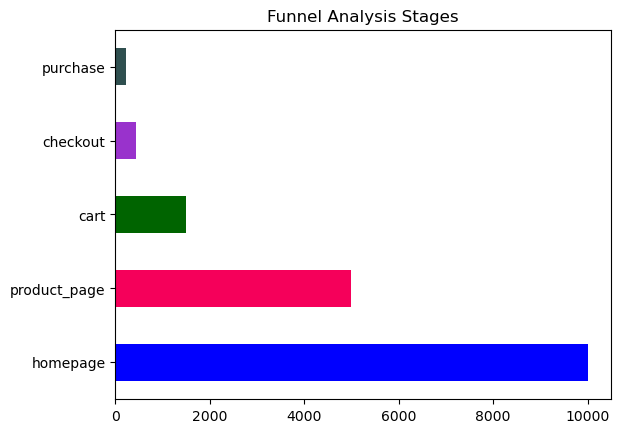

In [4]:
#Code by Lucas Abrahão https://www.kaggle.com/lucasabrahao/trabalho-manufatura-an-lise-de-dados-no-brasil

df["stage"].value_counts().plot.barh(color=['blue', '#f5005a', '#006400', '#9932CC', '#2F4F4F', '#1E90FF' ], title='Funnel Analysis Stages');

In [5]:
df["conversion"].value_counts()

True     13014
False     4161
Name: conversion, dtype: int64

#How many users are getting through each stage in the funnel.

In [6]:
dfgr = df.groupby('stage').count()['conversion'].reset_index().sort_values(by='conversion',ascending=False)
dfgr.style.background_gradient(cmap='PuOr')

,stage,conversion
2,homepage,10000
3,product_page,5000
0,cart,1500
1,checkout,450
4,purchase,225


#Respective numbers are above

In [7]:
#https://plotly.com/python/funnel-charts/

import plotly.express as px
data = dict(
    number=[10000, 5000, 1500, 450, 225],
    stage=["homepage", "product_page", "purchase", "checkout", "cart"])
fig = px.funnel(data, x='number', y='stage')
fig.show()

#Basic Funnel Chart with graph_objects trace go.Funnel

In [8]:
#Basic Funnel Chart with graph_objects trace go.Funnel
#https://plotly.com/python/funnel-charts/

from plotly import graph_objects as go

fig = go.Figure(go.Funnel(
    y = ["homepage", "product_page", "purchase", "checkout", "cart"],
    x = [10000, 5000, 1500, 450, 225],
    textposition = "inside",
    textinfo = "value+percent initial",
    opacity = 0.65, marker = {"color": ["deepskyblue", "lightsalmon", "tan", "teal", "silver"],
    "line": {"width": [4, 2, 2, 3, 1, 1], "color": ["wheat", "wheat", "blue", "wheat", "wheat"]}},
    connector = {"line": {"color": "royalblue", "dash": "dot", "width": 3}})
    )

fig.show()

#Basic Area Funnel Plot with plotly.express

In [9]:
import plotly.express as px
fig = px.funnel_area(names=["homepage", "product_page", "purchase", "checkout", "cart"],
                    values=[10000, 5000, 1500, 450, 225])
fig.show()

#Basic Area Funnel Plot with go.Funnelarea

In [10]:
from plotly import graph_objects as go

fig = go.Figure(go.Funnelarea(
    text = ["homepage", "product_page", "purchase", "checkout", "cart"],
    values = [10000, 5000, 1500, 450, 225]
    ))
fig.show()

#Set Marker Size and Color in Area Funnel Plots

In [11]:
from plotly import graph_objects as go

fig = go.Figure(go.Funnelarea(
      values = [10000, 5000, 1500, 450, 225], text = ["homepage", "product_page", "purchase", "checkout", "cart"],
      marker = {"colors": ["deepskyblue", "lightsalmon", "tan", "teal", "silver"],
                "line": {"color": ["wheat", "wheat", "blue", "wheat", "wheat"], "width": [0, 1, 5, 0, 4]}},
      textfont = {"family": "Old Standard TT, serif", "size": 13, "color": "black"}, opacity = 0.65))
fig.show()

#Pattern Fills

In [12]:
from plotly import graph_objects as go

colors = ["gold", "gold", "lightgreen", "lavender"]

fig = go.Figure(
    go.Funnelarea(
        labels=["homepage", "product_page", "purchase", "checkout", "cart"],
        values=[10000, 5000, 1500, 450, 225],
        textfont_size=20,
        marker=dict(colors=colors, pattern=dict(shape=["", "/", "", ""])),
    )
)
fig.show()

#Acknowledgements:

https://plotly.com/python/funnel-charts/